# Parte 2b: Modelo B (preentrenado, InsightFace `buffalo_l`)

> **Notebook auxiliar.** Se usa para trabajar en paralelo. Su contenido se integra en `2-train.ipynb`, que es la que se entrega.
> La lógica va en `src/lib/`; acá solo se llaman funciones. Los embeddings se guardan con `save_embeddings` (contrato en `src/lib/evaluation/embedding_store.py`) y la evaluación de `src/lib/evaluation/` se corre igual para el modelo A.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.dataset.clustering import default_algorithms, evaluate_clustering, project_tsne
from lib.dataset.faces import load_aligned, pose_angles
from lib.evaluation import (EmbeddingSet, best_scores, evaluate_identification, far_frr_curve, hardest_errors,
                            load_embeddings, make_pairs, most_confused, open_set_curve, rate_at_threshold, results_path,
                            save_embeddings, split_gallery, threshold_at_far, threshold_at_fpir, verification_metrics)
from lib.evaluation.cost import file_size_mb, ms_per_face, onnx_parameters
from lib.vision import OnnxFaceEmbedder, resolve_model_pack
from lib.vision.detection import DEFAULT_DETECTOR_FILE
from lib.vision.embedding import DEFAULT_RECOGNIZER_FILE

CONFIG = json.loads((ROOT / "splits" / "config.json").read_text(encoding="utf-8"))
ALIGNED_ROOT = ROOT / CONFIG["aligned_root"]
SEED = CONFIG["seed"]
INSIGHTFACE_ROOT = "~/.insightface"
MODEL = "insightface_buffalo_l"
splits = pd.read_csv(ROOT / "splits" / "splits.csv")
splits["split"].value_counts()

C:\Users\lucas\Documents\TUIA\IA 5.1 - Vision por Computadora\cv-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


split
train          9006
val_open       2003
val_closed     1980
test_closed    1974
test_open      1900
Name: count, dtype: int64

In [2]:
def load_faces(rows: pd.DataFrame) -> list[np.ndarray]:
    """Caras alineadas en BGR, tal como las guardó la Parte 1."""
    return load_aligned(rows["aligned_path"], ALIGNED_ROOT)


def show_pairs(frame: pd.DataFrame, paths: np.ndarray, labels: np.ndarray, suptitle: str, ncols: int = 8) -> None:
    """Grilla de pares (i, j) con su score: dos imágenes por par."""
    n = 2 * len(frame)
    if n == 0:
        print(f"{suptitle}: ninguno")
        return
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.8, nrows * 2.1), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    images = load_aligned(np.ravel(np.c_[paths[frame["i"]], paths[frame["j"]]]), ALIGNED_ROOT)
    for k, (ax, image) in enumerate(zip(axes.flat, images)):
        row = frame.iloc[k // 2]
        position = row["i"] if k % 2 == 0 else row["j"]
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(labels[position] + (f"\nscore {row['score']:.3f}" if k % 2 else ""), fontsize=7)
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 1. Descripción del modelo (3.2)

Se usa el paquete **`buffalo_l`** de InsightFace como **extractor de embeddings, sin reentrenar**. Tiene dos modelos ONNX que se usan en todo el proyecto:

| | Detector | Reconocedor |
|---|---|---|
| Archivo | `det_10g.onnx` | `w600k_r50.onnx` |
| Modelo | **SCRFD-10GF** (Guo et al., 2021, *Sample and Computation Redistribution for Efficient Face Detection*) | **IResNet-50** entrenada con **ArcFace** (Deng et al., 2019) |
| Datos de entrenamiento | WIDER FACE | **WebFace600K**: subconjunto limpio de WebFace260M con unas 600 mil identidades (WebFace12M, ~12 millones de imágenes) |
| Entrada | imagen completa (se redimensiona a 640×640) | cara alineada de 112×112, RGB, `(x − 127,5) / 127,5` |
| Salida | caja, score y 5 landmarks | embedding de **512** dimensiones |

- **Cómo se usa acá:** el detector y la alineación ya corrieron en la Parte 1 (2.4). Esta notebook lee las caras alineadas de `splits.csv` y solo corre el reconocedor, con `OnnxFaceEmbedder`. Es la misma clase y la misma normalización (`InputNormalization`) que va a usar `face_service.py`. En 2.3 se verificó que reproduce a `insightface` con una diferencia de 1e-7.
- **ArcFace** (*additive angular margin loss*): entrena un clasificador sobre las identidades de entrenamiento con los embeddings y los pesos de cada clase normalizados. A la clase correcta le suma un margen angular *m* (0,5 rad) antes de la softmax. Así, para acertar, la cara tiene que quedar más cerca de su clase de lo que exigiría una softmax común: el resultado son embeddings donde el coseno separa identidades, en general también las que el modelo no vio.
- **IResNet-50:** la ResNet-50 adaptada a caras del paper de ArcFace. Tiene BatchNorm y PReLU en cada bloque, la entrada de 112×112 sin *max pooling* inicial y una capa final BN → Dropout → FC → BN que reemplaza al *global average pooling* para conservar la información espacial de la cara.
- **Licencia:** el código de InsightFace es MIT, pero los **pesos preentrenados son solo para investigación y uso no comercial**. Sirven para este trabajo académico; una app comercial necesitaría otra licencia o un modelo propio, como el modelo A.

**Advertencia sobre las métricas.** WebFace260M se armó con fotos de celebridades de internet, igual que Pins. Es muy probable que varias de nuestras 105 personas, incluidas las de `test_open`, estén entre las identidades con las que se entrenó ArcFace. Para este modelo, el open-set no es del todo "identidades nunca vistas", y las métricas pueden ser optimistas respecto de lo que rendiría con las personas que registra la app. ArcFace también se usó en la Parte 1 para curar el dataset (duplicados, errores de etiqueta y outliers): se descartaron imágenes que no ubicaba bien en su clase, lo que también lo favorece.

In [3]:
MODEL_DIR = resolve_model_pack(root=INSIGHTFACE_ROOT)
RECOGNIZER = MODEL_DIR / DEFAULT_RECOGNIZER_FILE
DETECTOR = MODEL_DIR / DEFAULT_DETECTOR_FILE

embedder = OnnxFaceEmbedder.from_model_pack(root=INSIGHTFACE_ROOT)
pd.DataFrame({
    "archivo": [DETECTOR.name, RECOGNIZER.name],
    "parámetros (M)": [onnx_parameters(DETECTOR) / 1e6, onnx_parameters(RECOGNIZER) / 1e6],
    "tamaño (MB)": [file_size_mb(DETECTOR), file_size_mb(RECOGNIZER)],
}, index=["detector", "reconocedor"]).round(2)

,archivo,parámetros (M),tamaño (MB)
detector,det_10g.onnx,4.23,16.14
reconocedor,w600k_r50.onnx,43.59,166.31


## 2. Extracción de embeddings

Se calculan sobre todos los splits menos `train`: el modelo B no se entrena, y la evaluación es igual para ambos modelos, así que solo usa validación y test. Se guardan en `results/insightface_buffalo_l/embeddings.npz` con el contrato común.

In [4]:
eval_rows = splits[splits["split"] != "train"].reset_index(drop=True)
embeddings = embedder.embed(load_faces(eval_rows))

save_embeddings(
    EmbeddingSet(
        model=MODEL,
        paths=eval_rows["aligned_path"].to_numpy(),
        labels=eval_rows["identity"].to_numpy(),
        splits=eval_rows["split"].to_numpy(),
        embeddings=embeddings,
    ),
    results_path(ROOT, MODEL),
)
print(f"Embeddings: {embeddings.shape} {embeddings.dtype} | norma L2: {np.linalg.norm(embeddings, axis=1).mean():.4f}")

Embeddings: (7857, 512) float32 | norma L2: 1.0000


## 3. Evaluación (3.3)

A partir de acá todo se calcula sobre el `.npz`, sin saber qué modelo lo generó: estas mismas celdas se corren en `2-train.ipynb` para el modelo A.

| Qué | Split | Por qué |
|---|---|---|
| Verificación (pares) | `test_open` | Identidades que el modelo A nunca vio: es el escenario de la app, que registra personas nuevas. |
| Calibración del umbral | `val_open` (1:1) y `val_closed` + `val_open` (1:N) | El umbral no se calibra sobre el mismo conjunto en el que se reporta. |
| Identificación | galería de `val_closed`, probes de `test_closed`, desconocidos de `test_open` | Ver 3b. |
| Clustering | `test_open` y `test_closed` | |

In [5]:
emb_set = load_embeddings(results_path(ROOT, MODEL))
print(f"{emb_set.model}: {len(emb_set.labels)} embeddings de dimensión {emb_set.dim}")
parts = {split: emb_set.subset(split) for split in ["val_closed", "test_closed", "val_open", "test_open"]}
paths_of = {split: part.paths for split, part in parts.items()}

insightface_buffalo_l: 7857 embeddings de dimensión 512


### 3a. Verificación: ¿son la misma persona?

Se arman **5.000 pares positivos y 5.000 negativos** dentro de `test_open` (13 identidades) y lo mismo en `val_open` para calibrar. Los positivos se reparten por igual entre identidades, para que las personas con más fotos no pesen más; los negativos son pares al azar de personas distintas. Con 5.000 negativos, el FAR más chico que se puede medir es 2e-4, así que TAR@FAR = 1e-3 se apoya en solo 5 falsos positivos: es un número con bastante varianza (limitación anticipada en 2.1, por las pocas identidades).

,AUC,EER,umbral EER,TAR@FAR=0.01,TAR@FAR=0.001
val_open,0.99999,0.0018,0.22894,0.9998,0.9976
test_open,0.99996,0.0036,0.20089,0.9990,0.9952


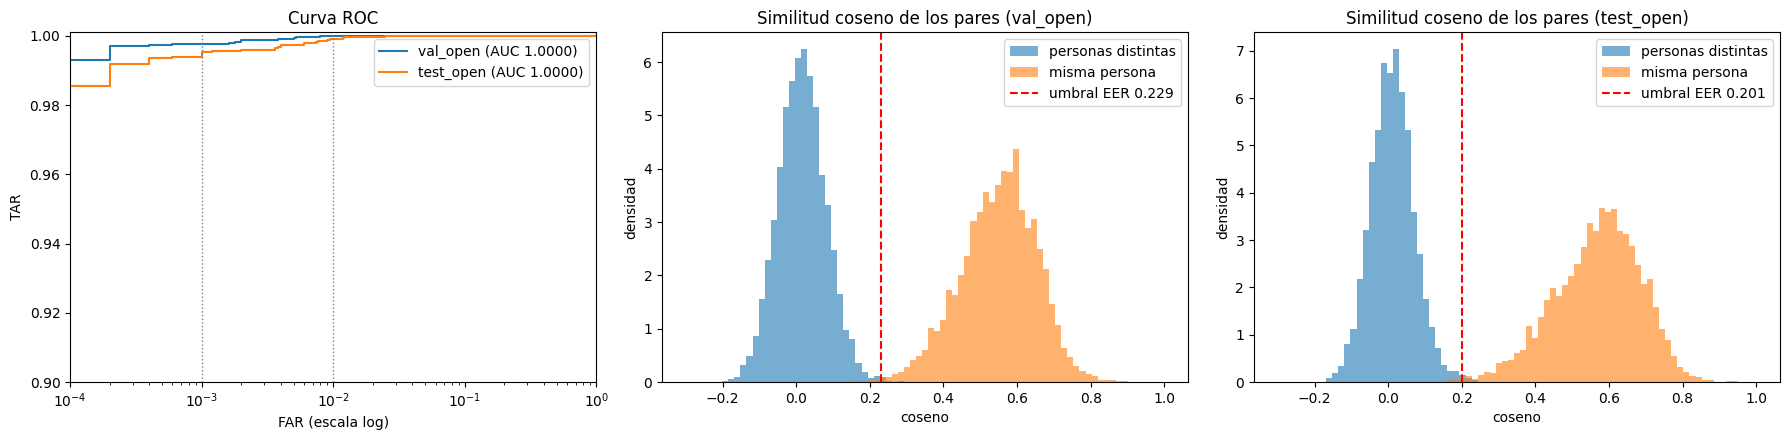

In [6]:
N_PAIRS = 5000
pairs = {split: make_pairs(parts[split].labels, N_PAIRS, seed=SEED) for split in ["val_open", "test_open"]}
scores = {split: p.scores(parts[split].embeddings) for split, p in pairs.items()}
verification = {split: verification_metrics(scores[split], pairs[split].same) for split in pairs}
display(pd.DataFrame({split: r.summary() for split, r in verification.items()}).T.round(5))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for split, r in verification.items():
    axes[0].plot(r.far, r.tar, label=f"{split} (AUC {r.auc:.4f})")
axes[0].set(xscale="log", xlim=(1e-4, 1), ylim=(0.9, 1.001), xlabel="FAR (escala log)", ylabel="TAR", title="Curva ROC")
for far in (1e-2, 1e-3):
    axes[0].axvline(far, color="gray", ls=":", lw=1)
axes[0].legend()
bins = np.linspace(-0.3, 1, 80)
for ax, split in zip(axes[1:], pairs):
    same = pairs[split].same
    ax.hist(scores[split][~same], bins=bins, alpha=0.6, density=True, label="personas distintas")
    ax.hist(scores[split][same], bins=bins, alpha=0.6, density=True, label="misma persona")
    ax.axvline(verification[split].eer_threshold, color="red", ls="--", label=f"umbral EER {verification[split].eer_threshold:.3f}")
    ax.set(title=f"Similitud coseno de los pares ({split})", xlabel="coseno", ylabel="densidad")
    ax.legend()
plt.tight_layout()
plt.show()

**Lectura.**
- En `test_open` el AUC es 0,99996 y el EER 0,36 %: con el umbral del EER se equivocan unos 18 pares de cada 5.000 de cada tipo. TAR@FAR = 1e-2 da 99,9 % y TAR@FAR = 1e-3 da 99,5 %. Los histogramas casi no se superponen: los pares de personas distintas se concentran alrededor de 0 y los de la misma persona alrededor de 0,6. Coincide con lo que se midió en 2.5 sobre todo el dataset (percentil 99 entre personas distintas 0,17 y percentil 1 de la misma persona 0,28).
- Validación y test dan valores parecidos: EER de 0,18 % y 0,36 %, con umbrales del EER de 0,229 y 0,201. Es razonable trasladar a test lo calibrado en validación (3c).
- Por lo dicho en la sección 1, son cifras optimistas para personas que ArcFace realmente no vio. Y TAR@FAR = 1e-3 se apoya en 5 falsos positivos de 5.000, así que su segunda cifra decimal no es confiable.

### 3c. Elección del umbral

La app compara cada cara contra **todos** los registros de la base y se queda con el más parecido (`FaceService.identify`); si ese score queda por debajo de `SIMILARITY_THRESHOLD`, devuelve `unknown`. Eso es **identificación 1:N**: un desconocido tiene N oportunidades de superar el umbral, una por cada registro. Por eso se comparan dos formas de calibrar, ambas en validación:

- **1:1:** sobre los pares de `val_open`, el umbral del EER y el que da FAR = 1e-3.
- **1:N:** se arma una galería como la de la app (5 imágenes por identidad de `val_closed`, 80 personas y 400 registros) y se usan como consultas el resto de `val_closed` (conocidos) y todo `val_open` (desconocidos). Para cada umbral se mide la **DIR** (*detection and identification rate*: conocidos aceptados con la identidad correcta) y la **FPIR** (*false positive identification rate*: desconocidos aceptados como alguien). Se elige el umbral con **FPIR = 1 %**.

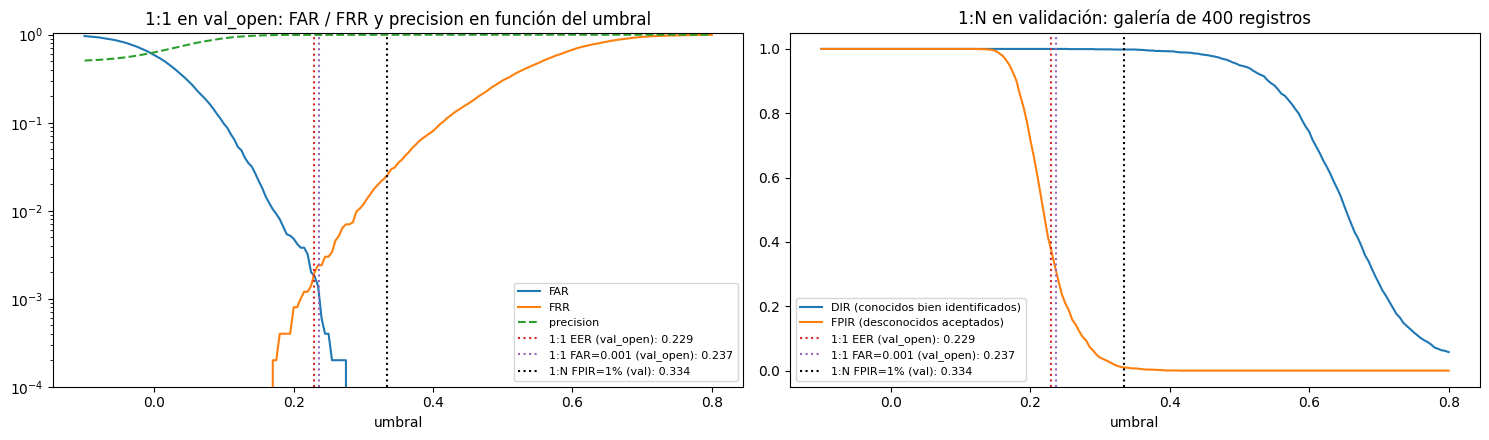

,umbral,FAR 1:1 (test_open),FRR 1:1 (test_open),FPIR 1:N (val),DIR 1:N (val)
criterio,,,,,
1:1 EER (val_open),0.2289,0.0006,0.0064,0.3834,1.0000
1:1 FAR=0.001 (val_open),0.2365,0.0004,0.0072,0.3120,1.0000
1:N FPIR=1% (val),0.3338,0.0000,0.0334,0.0100,0.9981


In [7]:
GALLERY_PER_IDENTITY = 5
TARGET_FAR = 1e-3
TARGET_FPIR = 0.01
val_gallery, val_known = split_gallery(parts["val_closed"].labels, GALLERY_PER_IDENTITY, seed=SEED)
gallery_emb = parts["val_closed"].embeddings[val_gallery]
gallery_labels = parts["val_closed"].labels[val_gallery]

known_best, known_correct = best_scores(gallery_emb, gallery_labels, parts["val_closed"].embeddings[val_known],
                                        parts["val_closed"].labels[val_known])
unknown_best, _ = best_scores(gallery_emb, gallery_labels, parts["val_open"].embeddings)

thresholds = {
    "1:1 EER (val_open)": verification["val_open"].eer_threshold,
    f"1:1 FAR={TARGET_FAR:g} (val_open)": threshold_at_far(scores["val_open"], pairs["val_open"].same, TARGET_FAR),
    f"1:N FPIR={TARGET_FPIR:.0%} (val)": threshold_at_fpir(unknown_best, TARGET_FPIR),
}

grid = np.linspace(-0.1, 0.8, 181)
curve_11 = far_frr_curve(scores["val_open"], pairs["val_open"].same, grid)
curve_1n = open_set_curve(known_best, known_correct, unknown_best, grid)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(curve_11["umbral"], curve_11["FAR"], label="FAR")
axes[0].plot(curve_11["umbral"], curve_11["FRR"], label="FRR")
axes[0].plot(curve_11["umbral"], curve_11["precision"], label="precision", ls="--")
axes[0].set(title="1:1 en val_open: FAR / FRR y precision en función del umbral", xlabel="umbral", yscale="log", ylim=(1e-4, 1.05))
axes[1].plot(curve_1n["umbral"], curve_1n["DIR"], label="DIR (conocidos bien identificados)")
axes[1].plot(curve_1n["umbral"], curve_1n["FPIR"], label="FPIR (desconocidos aceptados)")
axes[1].set(title=f"1:N en validación: galería de {len(gallery_labels)} registros", xlabel="umbral")
for ax in axes:
    for (name, value), color in zip(thresholds.items(), ["tab:red", "tab:purple", "black"]):
        ax.axvline(value, color=color, ls=":", label=f"{name}: {value:.3f}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for name, value in thresholds.items():
    row = rate_at_threshold(scores["test_open"], pairs["test_open"].same, value)
    row["FPIR 1:N (val)"] = float((unknown_best >= value).mean())
    row["DIR 1:N (val)"] = float(((known_best >= value) & known_correct).mean())
    rows.append({"criterio": name, **row})
display(pd.DataFrame(rows).set_index("criterio").rename(columns={"FAR": "FAR 1:1 (test_open)", "FRR": "FRR 1:1 (test_open)"}).round(4))

**Decisión.**
- **Los umbrales 1:1 no sirven para la app.** El del EER (0,229) y el de FAR = 1e-3 (0,237) funcionan muy bien con pares sueltos: en `test_open` aceptan solo el 0,06 % y el 0,04 % de los impostores. Pero en el escenario 1:N aceptan como alguien registrado al **38 % y al 31 % de los desconocidos** de validación. Cada desconocido se compara contra 400 registros, y alcanza con que uno supere el umbral. Se ve en el gráfico de la derecha: la FPIR recién se hace chica cerca de 0,3.
- **Se elige el umbral 1:N con FPIR = 1 %: `SIMILARITY_THRESHOLD = 0.334`** (`SIMILARITY_METRIC = cosine`). La DIR en validación sigue en 99,8 %, porque los conocidos tienen su mejor score muy por encima (la curva DIR no empieza a bajar hasta pasar 0,4). El costo está en 1:1: con este umbral, la FRR de pares sueltos de `test_open` sube de 0,7 % a 3,3 %. La app no compara pares sueltos, así que aceptamos ese costo.
- El umbral depende del tamaño de la galería. Con más personas registradas, un desconocido tiene más chances de superarlo y habría que recalibrar; con las 3 a 5 identidades de la demo (4.4), 0,334 es conservador. También es propio de este modelo: si se elige el modelo A, se calibra igual sobre sus embeddings.

In [8]:
THRESHOLD = thresholds[f"1:N FPIR={TARGET_FPIR:.0%} (val)"]
print(f"SIMILARITY_THRESHOLD = {THRESHOLD:.3f}  (SIMILARITY_METRIC = cosine)")

SIMILARITY_THRESHOLD = 0.334  (SIMILARITY_METRIC = cosine)


### 3b. Identificación: ¿quién es?

- **Galería:** las mismas 5 imágenes por identidad de `val_closed` de 3c (80 personas, 400 registros), como si se hubieran cargado con `/insert`. Se toman de `val_closed` y no de `test_closed` porque la Parte 1 asignó cada grupo de copias de una misma foto entero a un split: así ninguna consulta tiene una copia suya en la galería.
- **Consultas conocidas:** todo `test_closed` (1.974 imágenes de las mismas 80 personas).
- **Consultas desconocidas:** todo `test_open` (13 personas que no están en la galería). Lo correcto es devolver `unknown`.
- **Top-1 y Top-5** se miden sin umbral, solo con conocidos. **Precision, recall y F1 macro** se miden con el umbral elegido, sobre conocidos y desconocidos, promediando sobre las 80 identidades registradas: aceptar a un desconocido como alguien baja la precision de esa persona.
- Se comparan dos formas de usar la galería: **max** (el registro más parecido, como `identify` de la app) y **mean** (promedio de los embeddings de cada persona, una de las mejoras opcionales de 4.5).

In [9]:
identification = {
    aggregate: evaluate_identification(
        gallery_emb, gallery_labels,
        parts["test_closed"].embeddings, parts["test_closed"].labels,
        THRESHOLD,
        parts["test_open"].embeddings, parts["test_open"].labels,
        aggregate=aggregate,
    )
    for aggregate in ["max", "mean"]
}
display(pd.DataFrame({f"galería: {a}": r.summary() for a, r in identification.items()}).round(4))

predictions = identification["max"].predictions
print("Conocidos identificados como otra persona (verdadera → predicha):")
display(most_confused(predictions[predictions["tipo"] == "conocido"]))
print("Desconocidos aceptados como alguien registrado:")
display(most_confused(predictions[predictions["tipo"] == "desconocido"]))

,galería: max,galería: mean
Top-1,1.0000,1.0000
Top-5,1.0000,1.0000
precision (macro),0.9943,0.9992
recall (macro),0.9988,0.9993
F1 (macro),0.9962,0.9992
conocidos: correctos,0.9990,0.9995
conocidos: rechazados,0.0010,0.0005
conocidos: otra identidad,0.0000,0.0000
desconocidos rechazados,0.9921,0.9989


Conocidos identificados como otra persona (verdadera → predicha):


,identidad,predicha,veces


Desconocidos aceptados como alguien registrado:


,identidad,predicha,veces
0,Emilia Clarke,Miley Cyrus,10
1,Emilia Clarke,melissa fumero,4
2,Emilia Clarke,alycia dabnem carey,1


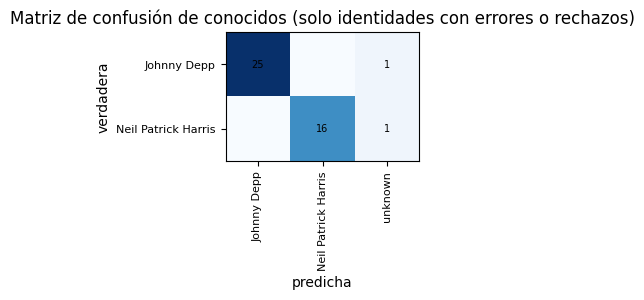

In [10]:
# Matriz de confusión: con 80 identidades no se lee entera; se muestran las filas y columnas con algún error
known = predictions[predictions["tipo"] == "conocido"]
confusion = pd.crosstab(known["verdadera"], known["predicha"])
involved = sorted(set(known.loc[known["verdadera"] != known["predicha"], "verdadera"])
                  | set(known.loc[known["verdadera"] != known["predicha"], "predicha"]))
if involved:
    sub = confusion.reindex(index=[i for i in involved if i in confusion.index],
                            columns=[c for c in involved if c in confusion.columns], fill_value=0)
    fig, ax = plt.subplots(figsize=(1 + 0.5 * sub.shape[1], 1 + 0.4 * sub.shape[0]))
    ax.imshow(sub, cmap="Blues")
    ax.set_xticks(range(sub.shape[1]), sub.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(sub.shape[0]), sub.index, fontsize=8)
    for (r, c), v in np.ndenumerate(sub.to_numpy()):
        if v:
            ax.text(c, r, v, ha="center", va="center", fontsize=7)
    ax.set(title="Matriz de confusión de conocidos (solo identidades con errores o rechazos)", xlabel="predicha", ylabel="verdadera")
    plt.show()
else:
    print("Todas las consultas conocidas se identificaron o rechazaron sin confundir identidades")

**Lectura.**
- **Conocidos:** Top-1 y Top-5 son 100 %: sin umbral, las 1.974 consultas de `test_closed` encuentran primero a su persona. Con el umbral de 0,334 se acepta bien el 99,9 % y se rechazan 2 como `unknown`; ninguna se confunde con otra persona registrada. Por eso la matriz de confusión solo muestra esos dos rechazos.
- **Desconocidos:** se rechaza el 99,2 % de `test_open` (se aceptan 15 de 1.900), muy cerca del 99 % calibrado en validación. Las 15 son fotos de Emilia Clarke, aceptadas como Miley Cyrus (10), Melissa Fumero (4) y Alycia Debnam-Carey (1). Emilia Clarke y Miley Cyrus son uno de los diez pares de identidades más parecidos de 2.5.
- **Precision, recall y F1 macro** (0,994, 0,999 y 0,996): la precision baja por esas 15 aceptaciones, que cuentan como falsos positivos de esas tres personas; el recall, por los dos rechazos.
- **max contra mean:** comparar contra el promedio de los 5 registros de cada persona sube el rechazo de desconocidos de 99,2 % a 99,9 % sin perder conocidos. Una explicación posible es que el promedio depende menos de un único registro atípico que el máximo. Pero el umbral se calibró con max: para usar el promedio en la app (mejora opcional de 4.5) habría que recalibrarlo con ese criterio.
- Como se anotó en 2.7, fotos de una misma sesión pueden quedar en `val_closed` (galería) y en `test_closed` (consultas). Eso puede inflar algo el closed-set.

### 3d. Clustering de embeddings

Igual que en 2.5: proyección t-SNE y K-Means, aglomerativo y DBSCAN comparados con las etiquetas (ARI, NMI, silhouette coseno), con las funciones de `lib.dataset.clustering`. Se mide sobre `test_open` (13 personas que el modelo A no vio) y sobre `test_closed` (80 personas). DBSCAN usa el mismo `eps = 0,5` que en 2.5: es una distancia coseno pensada para ArcFace, y para el modelo A puede no ser adecuada.

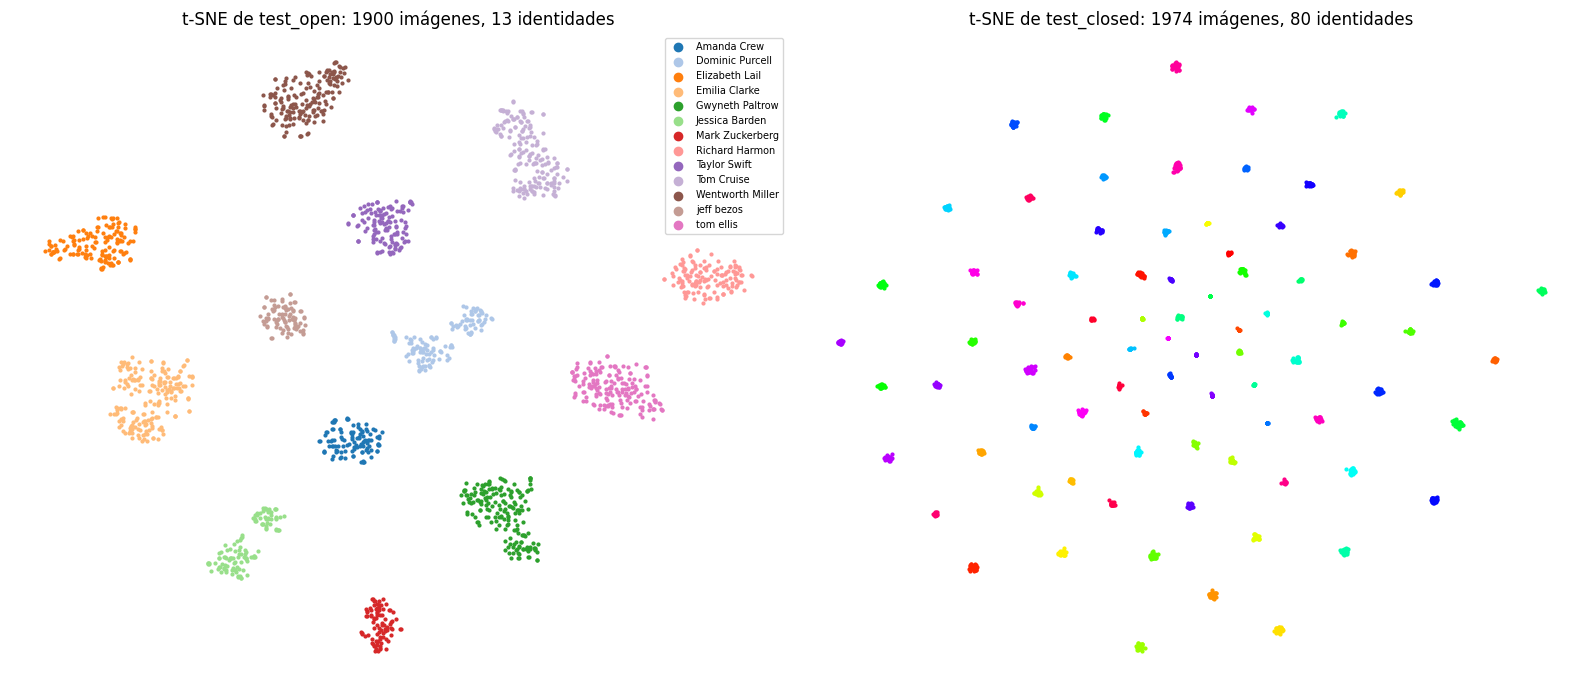

,algoritmo,clusters,ruido,ARI,NMI,silhouette
split,,,,,,
test_open,Etiquetas reales,13,0,1.000,1.000,0.515
test_open,K-Means,13,0,1.000,1.000,0.515
test_open,"Aglomerativo (coseno, average)",13,0,1.000,1.000,0.515
test_open,"DBSCAN (coseno, eps=0.5)",13,15,0.993,0.992,0.519
test_closed,Etiquetas reales,80,0,1.000,1.000,0.490
test_closed,K-Means,80,0,0.975,0.995,0.469
test_closed,"Aglomerativo (coseno, average)",80,0,1.000,1.000,0.490
test_closed,"DBSCAN (coseno, eps=0.5)",80,39,0.966,0.985,0.499


In [11]:
clustering = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, split in zip(axes, ["test_open", "test_closed"]):
    part = parts[split]
    clustering[split], _ = evaluate_clustering(part.embeddings, part.labels, default_algorithms(seed=SEED, dbscan_eps=0.5))
    points = project_tsne(part.embeddings, seed=SEED)
    identities = np.unique(part.labels)
    colors = plt.cm.tab20(np.arange(len(identities)) % 20) if len(identities) <= 20 else \
        plt.cm.hsv(np.random.default_rng(SEED).permutation(len(identities)) / len(identities))
    for color, identity in zip(colors, identities):
        mask = part.labels == identity
        ax.scatter(points[mask, 0], points[mask, 1], s=4, color=color, label=identity if len(identities) <= 20 else None)
    ax.set_title(f"t-SNE de {split}: {len(part.labels)} imágenes, {len(identities)} identidades")
    ax.axis("off")
axes[0].legend(fontsize=7, markerscale=3, loc="best")
plt.tight_layout()
plt.show()
display(pd.concat(clustering, names=["split"]).droplevel(1).round(3))

**Lectura.**
- **`test_open`:** las 13 personas forman islas separadas. K-Means y el aglomerativo recuperan la partición exacta (ARI 1,000) y DBSCAN deja 15 imágenes como ruido (ARI 0,993). El silhouette con las etiquetas reales es 0,515.
- **`test_closed`:** con 80 personas, el aglomerativo vuelve a dar ARI 1,000; K-Means baja a 0,975 por el problema de 2.5 (fija k y supone grupos de tamaño parecido), y DBSCAN a 0,966 con 39 imágenes de ruido. El silhouette (0,490) es el mismo que en 2.5 (0,487).
- **Islas con dos lóbulos:** Tom Cruise, Dominic Purcell, Jessica Barden, Gwyneth Paltrow y Emilia Clarke muestran subgrupos dentro de su isla, sin mezclarse con otras personas. Son los subgrupos por época o condiciones de captura de 2.5, y coinciden con las identidades que más falsos negativos tienen después de Taylor Swift (3e).
- Es la referencia de separación contra la que se compara el modelo A en `2-train.ipynb`, con las mismas métricas y el mismo `eps`.

### 3e. Análisis de errores

Errores de verificación sobre los pares de `test_open` con el umbral elegido: **falsos positivos** (personas distintas aceptadas como la misma) y **falsos negativos** (la misma persona rechazada). Para tener ejemplos aunque haya pocos errores, se muestran los negativos con score más alto y los positivos con score más bajo, marcando cuáles quedan del lado equivocado del umbral.

Para las hipótesis se miden en cada imagen las condiciones que 2.5 señaló como difíciles: **pose** (indicador de yaw con los landmarks de `splits.csv`), **blanco y negro** y **brillo** de la zona central de la cara.

Con umbral 0.334: 0 falsos positivos de 5000 negativos y 167 falsos negativos de 5000 positivos


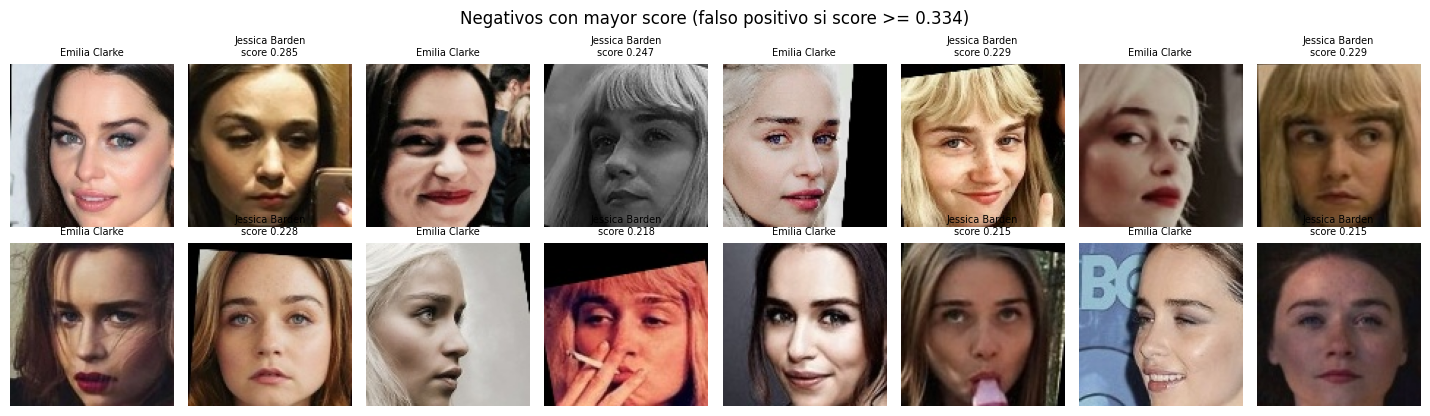

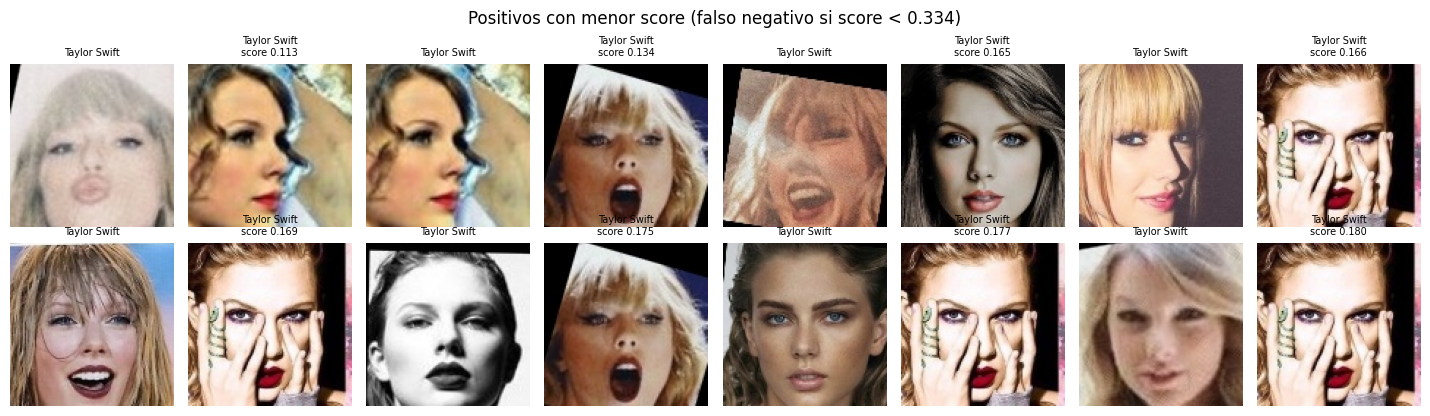

In [12]:
test_pairs, test_scores = pairs["test_open"], scores["test_open"]
labels_test, paths_test = parts["test_open"].labels, paths_of["test_open"]
fp, fn = hardest_errors(test_pairs, test_scores, THRESHOLD, top=10_000)
print(f"Con umbral {THRESHOLD:.3f}: {len(fp)} falsos positivos de {(~test_pairs.same).sum()} negativos "
      f"y {len(fn)} falsos negativos de {test_pairs.same.sum()} positivos")

hardest_negatives, _ = hardest_errors(test_pairs, test_scores, -np.inf, top=8)
_, hardest_positives = hardest_errors(test_pairs, test_scores, np.inf, top=8)
show_pairs(hardest_negatives, paths_test, labels_test, f"Negativos con mayor score (falso positivo si score >= {THRESHOLD:.3f})")
show_pairs(hardest_positives, paths_test, labels_test, f"Positivos con menor score (falso negativo si score < {THRESHOLD:.3f})")

In [13]:
# Condiciones de captura de cada imagen de test_open
meta = splits.set_index("aligned_path").loc[paths_test]
faces_test = load_aligned(paths_test, ALIGNED_ROOT)
center = (slice(36, 100), slice(28, 84))   # zona central de la cara, la misma de 2.3
conditions = pd.DataFrame({
    "|yaw|": pose_angles(meta)["yaw_proxy"].abs().to_numpy(),
    "blanco y negro": [bool(np.ptp(f.astype(int), axis=2).max() <= 8) for f in faces_test],
    "brillo central": [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)[center].mean() for f in faces_test],
})

def pair_conditions(frame: pd.DataFrame) -> pd.Series:
    """Peor condición de las dos imágenes de cada par, promediada sobre los pares."""
    i, j = frame["i"].to_numpy(), frame["j"].to_numpy()
    return pd.Series({
        "pares": len(frame),
        "|yaw| máx. del par": np.maximum(conditions["|yaw|"].to_numpy()[i], conditions["|yaw|"].to_numpy()[j]).mean(),
        "% con perfil (|yaw| > 0,35)": 100 * (np.maximum(conditions["|yaw|"].to_numpy()[i], conditions["|yaw|"].to_numpy()[j]) > 0.35).mean(),
        "% con B/N": 100 * (conditions["blanco y negro"].to_numpy()[i] | conditions["blanco y negro"].to_numpy()[j]).mean(),
        "brillo mín. del par": np.minimum(conditions["brillo central"].to_numpy()[i], conditions["brillo central"].to_numpy()[j]).mean(),
    })

all_pairs = pd.DataFrame({"i": test_pairs.i, "j": test_pairs.j, "same": test_pairs.same, "score": test_scores})
low_positives = all_pairs[all_pairs["same"]].nsmallest(100, "score")
groups = {
    "todos los positivos": all_pairs[all_pairs["same"]],
    "100 positivos de menor score": low_positives,
    "falsos negativos": fn,
    "todos los negativos": all_pairs[~all_pairs["same"]],
    "falsos positivos": fp,
}
display(pd.DataFrame({name: pair_conditions(frame) for name, frame in groups.items() if len(frame)}).round(2))

,todos los positivos,100 positivos de menor score,falsos negativos,todos los negativos
pares,5000.00,100.00,167.00,5000.00
|yaw| máx. del par,0.22,0.35,0.35,0.23
"% con perfil (|yaw| > 0,35)",17.12,32.00,33.53,17.10
% con B/N,9.22,9.00,13.77,9.84
brillo mín. del par,116.86,115.17,114.76,114.64


**Lectura.**
- **Falsos positivos:** con el umbral de 0,334 no hay ninguno en `test_open` (0 de 5.000). Los negativos de score más alto llegan a 0,285 y son todos Emilia Clarke contra Jessica Barden: actrices de edad, color de pelo y rasgos parecidos, uno de los diez pares de identidades más cercanos de 2.5. Quedan a 0,05 del umbral: es el tipo de confusión que podría aparecer con más personas registradas.
- **Falsos negativos:** son 167 de 5.000 (3,3 %), el costo de un umbral pensado para 1:N. Se concentran mucho: **Taylor Swift tiene 88**, el 23 % de sus pares positivos, contra menos del 5 % de cualquier otra persona (siguen Jessica Barden con 4,9 % y Tom Cruise con 4,7 %). Involucran 198 imágenes distintas y algunas aparecen en hasta 10 pares: hay fotos difíciles que se repiten en varios errores.
- **Hipótesis, a partir de la grilla y la tabla:**
  - **Pose:** el 34 % de los falsos negativos tiene una cara de perfil, contra el 17 % de todos los pares positivos; es la condición que 2.5 ya marcaba como la que más aleja una foto de su identidad.
  - **Oclusión y expresión:** la foto con las manos sobre la cara aparece en cuatro de los ocho peores pares, y las de la boca muy abierta en otros tres.
  - **Baja resolución:** el peor par incluye una foto pixelada y lavada.
  - **Variación real de apariencia:** Taylor Swift cambia mucho de peinado, color de pelo y maquillaje según la época, y sus fotos tienen una similitud mediana de 0,67 con su centroide, contra 0,76 de una foto típica del dataset (2.5).
  - **Posible error de etiqueta:** en la grilla hay una foto etiquetada como Taylor Swift (morocha, de cejas gruesas) que a simple vista no parece ella. Si lo es, la auditoría de 2.5 no la atrapó porque su similitud con el centroide supera el corte de 0,3.
  - **Color e iluminación** pesan poco: el blanco y negro sube de 9 % a 14 % en los falsos negativos, y el brillo mínimo del par es el mismo (115 contra 117).
- Para la app, conviene registrar varias fotos por persona, frontales y sin oclusiones. Una galería con poses variadas debería cubrir mejor los perfiles que una sola foto.

### 3f. Costo computacional

Tiempo por rostro del reconocedor en CPU (`CPUExecutionProvider`), medido sobre 200 caras: **de a una** (el caso de la app, que procesa cada cara por separado) y en lotes de 64 (el caso de las notebooks). No incluye la detección, que es la misma para ambos modelos.

In [14]:
timing_faces = load_faces(eval_rows.sample(200, random_state=SEED))
cost = pd.Series({
    "parámetros (M)": onnx_parameters(RECOGNIZER) / 1e6,
    "tamaño (MB)": file_size_mb(RECOGNIZER),
    "dimensión del embedding": embedder.dim,
    "ms/rostro en CPU (lote 1)": ms_per_face(embedder, timing_faces, batch_size=1),
    "ms/rostro en CPU (lote 64)": ms_per_face(embedder, timing_faces, batch_size=64),
}, name=MODEL)
cost.round(2).to_frame()

,insightface_buffalo_l
parámetros (M),43.59
tamaño (MB),166.31
dimensión del embedding,512.00
ms/rostro en CPU (lote 1),95.64
ms/rostro en CPU (lote 64),87.53


## 4. Resumen del modelo B

Columna del modelo B para la tabla comparativa de `2-train.ipynb` (3.4) y de la descripción del PR.

In [15]:
summary = pd.Series({
    **{f"verificación: {k}": v for k, v in verification["test_open"].summary().items()},
    "umbral elegido (1:N, FPIR 1 % en val)": THRESHOLD,
    **{f"identificación: {k}": v for k, v in identification["max"].summary().items()},
    "silhouette test_open (etiquetas)": clustering["test_open"].iloc[0]["silhouette"],
    "ARI aglomerativo test_open": clustering["test_open"].iloc[2]["ARI"],
    "ARI aglomerativo test_closed": clustering["test_closed"].iloc[2]["ARI"],
    **cost.to_dict(),
}, name=MODEL)
summary_path = results_path(ROOT, MODEL).with_name("summary.json")
summary_path.write_text(summary.to_json(indent=2, force_ascii=False), encoding="utf-8")
summary.round(5).to_frame()

,insightface_buffalo_l
verificación: AUC,0.99996
verificación: EER,0.00360
verificación: umbral EER,0.20089
verificación: TAR@FAR=0.01,0.99900
verificación: TAR@FAR=0.001,0.99520
"umbral elegido (1:N, FPIR 1 % en val)",0.33377
identificación: Top-1,1.00000
identificación: Top-5,1.00000
identificación: precision (macro),0.99429
identificación: recall (macro),0.99878


**Lectura.**
- Resultados del modelo B: AUC 0,99996, EER 0,36 % y TAR@FAR = 1e-3 de 99,5 % en verificación; Top-1 100 %, F1 macro 0,996 y 99,2 % de desconocidos rechazados en identificación; ARI 1,000 con el aglomerativo.
- **Costo:** 43,6 M de parámetros y 166 MB. En esta ejecución tardó 96 ms por rostro de a una cara y 88 ms en lotes de 64, en una notebook sin GPU para onnxruntime; en otra ejecución en la misma máquina dio 46 ms, así que la medición depende mucho de la carga. Los lotes casi no ayudan porque onnxruntime ya reparte una sola cara entre todos los núcleos. Unas 10 caras por segundo alcanzan para la app. Para comparar con el modelo A, los dos tiempos se tienen que medir en la misma corrida de `2-train.ipynb`.
- Hay que leerlo con cautela: las personas de Pins probablemente estén en WebFace600K y ArcFace se usó para curar el dataset (sección 1). Para la comparación con el modelo A, lo que interesa es cuánto se puede acercar con 9.006 imágenes de 80 personas, contra millones de imágenes de 600 mil.
- **Si se elige para la app:** `models/w600k_r50.onnx` (se descarga con `buffalo_l` de InsightFace), `EMBEDDING_DIM=512`, `FACE_SIZE=112`, `SIMILARITY_METRIC=cosine` y `SIMILARITY_THRESHOLD=0.334`. La licencia es no comercial.